# Scenario prediction: what if a district gets greener (or more built-up)?

`ΔLST = predict(scenario inputs) − predict(current inputs)` per pixel (slide 18, CONTRACTS section 3), with the
efficient student from `01_efficient` and, for comparison, the Member 2 teacher.

**Design, from the handovers:**
- The target is an anomaly from each scene's median, so a scenario changes a **region** (here the central 32 × 32 block
  ≈ 1.9 km of each test city, or only its built-up / tree pixels) and is read against the unchanged rest.
- Levers move in **physical units** and stay in range; NDVI, NDBI and `built_share` move **together**, with the
  steps taken from Member 1's typical values (built-up median NDVI 0.27, NDBI 0.01, built_share 0.34; tree 0.61, −0.19, 0.04).
- Reality checks (observed, Member 1 §7.2): green → built **+0.36 °C** (95 % CI 0.29–0.44, +0.3 to +0.9 by climate),
  built → green **−0.42 °C** (−0.49 to −0.38). SHAP (Member 2 §6): +0.1 NDVI ≈ −0.11 °C, +0.1 built_share ≈ +0.22 °C.
- Limits: the red/NIR bands, the 122 hyperspectral bands and the thermal context stay as they are, so the response
  is damped. Results are **modelled estimates, not causal guarantees**.

In [1]:
import json, time, warnings, h5py, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path
from torch.utils.data import DataLoader
from urbanheat.config import load_config
from urbanheat.data.dataset import PatchDataset
from urbanheat.efficient import benchmark, distill, lite
from urbanheat.models import baselines as B, train as T
warnings.filterwarnings("ignore")
cfg = load_config()
H5 = Path(cfg["data"]["processed_dir"]) / f"urbanheat_v{cfg['harmonize']['version']}.h5"
RUNS = Path(cfg["runs_dir"])
plt.rcParams["figure.dpi"] = 90
torch.set_num_threads(4)

from urbanheat.contracts import Scenario
from urbanheat.scenarios import engine
ds_test = PatchDataset(H5, "test")
prep_test = distill.Prepared(ds_test)
STUDENT = "m3_lite32_kd"
student, teacher = lite.load(RUNS / STUDENT), lite.load(RUNS / "cnn_robust_fusion_cnn_s0")
with h5py.File(H5) as f:
    landcover = {pid: f["pairs"][pid]["landcover"][:] for pid in ds_test.pairs}
    climate = {pid: f["pairs"][pid].attrs["climate_group"] for pid in ds_test.pairs}
print(len(ds_test.pairs), "test cities")

56 test cities


In [2]:
BUILT, TREE = 50, 10                                   # ESA WorldCover classes
SCENARIOS = {                                          # (scenario, which pixels of the central block change)
    "greening +0.1 NDVI": (Scenario("greening", {"NDVI": 0.1, "NDBI": -0.06}), None),
    "built -> green": (Scenario("built_to_green", {"NDVI": 0.34, "NDBI": -0.20, "built_share": -0.30}), BUILT),
    "green -> built": (Scenario("green_to_built", {"NDVI": -0.34, "NDBI": 0.20, "built_share": 0.30}), TREE),
    "built_share +0.1 only": (Scenario("densify", {"built_share": 0.1}), None),
    "NDVI +0.1 only": (Scenario("ndvi_only", {"NDVI": 0.1}), None),
}

def centre(shape, size=32):
    m = np.zeros(shape, bool); r, c = (shape[0] - size) // 2, (shape[1] - size) // 2
    m[max(r, 0):r + size, max(c, 0):c + size] = True
    return m

rows, maps = [], {}
for name, (sc, cls) in SCENARIOS.items():
    for label, model, d in [("student", student, prep_test), ("teacher", teacher, ds_test)]:
        for pid in d.pairs:
            where = centre(landcover[pid].shape) & (landcover[pid] == cls if cls is not None else True)
            if not (where & d.scene(pid)["mask"]).any():
                continue
            dl = engine.delta_lst(model, d, pid, sc, where=where)
            inside = where & np.isfinite(dl)
            rows.append(dict(scenario=name, model=label, pair_id=pid, climate=climate[pid], n=int(inside.sum()),
                             mean_in=float(dl[inside].mean()), mean_out=float(np.nanmean(dl[~where]))))
            maps[(name, label, pid)] = dl
res = pd.DataFrame(rows)
summary = res.groupby(["scenario", "model"]).apply(
    lambda g: pd.Series(dict(cities=len(g), pixels=g.n.sum(), dLST_changed_px=np.average(g.mean_in, weights=g.n),
                             dLST_rest=g.mean_out.mean()))).unstack("model")
summary.round(3)

cities           pixels          dLST_changed_px  \
model                 student teacher  student  teacher         student   
scenario                                                                  
NDVI +0.1 only           56.0    56.0  52468.0  52468.0          -0.027   
built -> green           55.0    55.0  15721.0  15721.0          -0.155   
built_share +0.1 only    56.0    56.0  52468.0  52468.0          -0.017   
green -> built           56.0    56.0  19050.0  19050.0           0.197   
greening +0.1 NDVI       56.0    56.0  52468.0  52468.0          -0.086   

                              dLST_rest          
model                 teacher   student teacher  
scenario                                         
NDVI +0.1 only         -0.001     0.002   0.000  
built -> green          0.176     0.004  -0.002  
built_share +0.1 only  -0.014     0.003   0.002  
green -> built         -0.045    -0.003   0.002  
greening +0.1 NDVI     -0.002     0.005   0.000

## Compared with the observed land-cover change

In [3]:
obs = pd.DataFrame({"observed (Member 1, median, 95 % CI)": {"green -> built": "+0.36 (0.29 – 0.44)",
                                                             "built -> green": "−0.42 (−0.49 – −0.38)"}})
cmp = summary.loc[["green -> built", "built -> green"], "dLST_changed_px"].round(2).join(obs)
cmp

,student,teacher,"observed (Member 1, median, 95 % CI)"
scenario,,,
green -> built,0.20,-0.04,+0.36 (0.29 – 0.44)
built -> green,-0.15,0.18,−0.42 (−0.49 – −0.38)


In [4]:
by_climate = res[res.model == "student"].groupby(["scenario", "climate"]).apply(
    lambda g: np.average(g.mean_in, weights=g.n)).unstack("climate").round(2)
by_climate

climate,arid,cold,temperate,tropical
scenario,,,,
NDVI +0.1 only,-0.08,-0.03,-0.03,-0.02
built -> green,-0.26,-0.17,-0.17,-0.10
built_share +0.1 only,-0.16,-0.05,-0.02,0.02
green -> built,0.35,0.15,0.11,0.20
greening +0.1 NDVI,-0.20,-0.08,-0.07,-0.07


## One test city: ΔLST map for 'built → green' in the centre

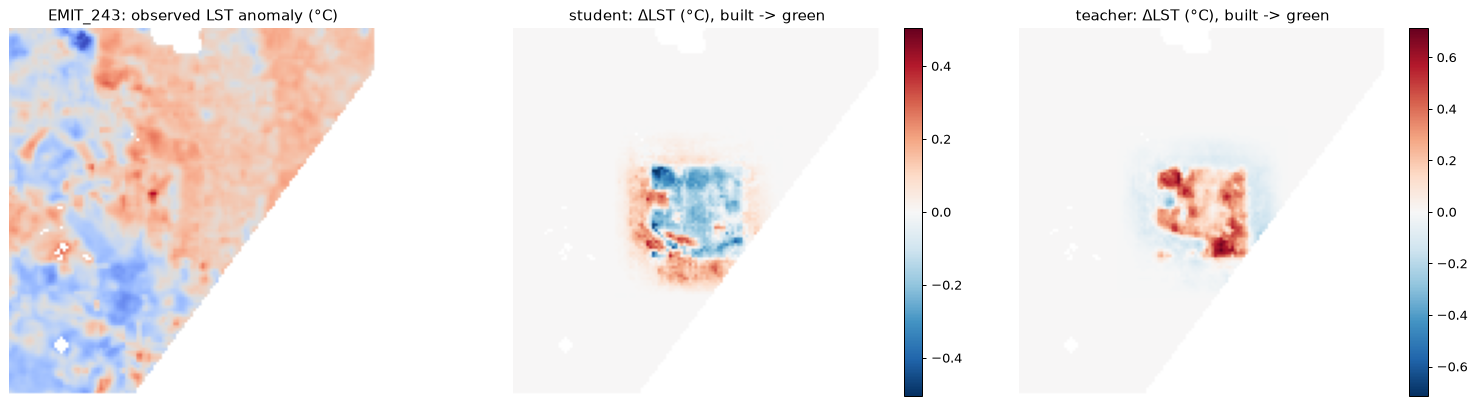

['EMIT_243_built_to_green.tif', 'EMIT_243_densify.tif', 'EMIT_243_green_to_built.tif', 'EMIT_243_greening.tif', 'EMIT_243_ndvi_only.tif']


In [5]:
name = "built -> green"
pid = max((k[2] for k in maps if k[0] == name and k[1] == "student"), key=lambda p: (landcover[p] == BUILT).sum())
s = prep_test.scene(pid)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].imshow(np.where(s["mask"], s["y"], np.nan), cmap="coolwarm"); ax[0].set_title(f"{pid}: observed LST anomaly (°C)")
for a, label in zip(ax[1:], ["student", "teacher"]):
    dl = maps[(name, label, pid)]; lim = np.nanmax(np.abs(dl)) or 1
    im = a.imshow(dl, cmap="RdBu_r", vmin=-lim, vmax=lim); plt.colorbar(im, ax=a, fraction=0.046)
    a.set_title(f"{label}: ΔLST (°C), {name}")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
OUT = RUNS / STUDENT / "scenarios"; OUT.mkdir(exist_ok=True)
for (n, label, p), dl in maps.items():
    if label == "student" and p == pid:
        engine.write_geotiff(OUT / f"{p}_{SCENARIOS[n][0].name}.tif", dl, H5, p, SCENARIOS[n][0])
print(sorted(x.name for x in OUT.glob("*.tif")))

## Summary (56 test cities, central 32×32 block changed, the rest unchanged)

| Scenario | Student ΔLST (°C) | Teacher ΔLST (°C) | Observed (Member 1) |
|---|---|---|---|
| green → built | **+0.20** | −0.04 (wrong sign) | +0.36 (0.29 – 0.44) |
| built → green | **−0.15** | +0.18 (wrong sign) | −0.42 (−0.49 – −0.38) |
| greening +0.1 NDVI (NDBI −0.06) | −0.09 | −0.00 | – |

- The student has the observed sign for both land-cover changes, at about half the observed size. The teacher's signs are wrong, because its NDVI/NDBI inputs were badly normalised.
- Pixels outside the changed block move by under 0.005 °C, so the response stays local.
- The response is largest in arid cities (green → built +0.35, built → green −0.26) and smallest in tropical ones.
- Why the response is damped: the thermal-context input (last season's LST) is held fixed, and the linked bands (red/NIR, hyperspectral) do not change.
- These are modelled estimates of surface temperature, not causal guarantees. The GeoTIFFs are in `runs/m3_lite32_kd/scenarios/`.
